# World's largest islands

This dataset `largest-islands.csv` contains information about the 100 largest islands in the world. The unit for the `area` column is km2.

In [1]:
# FOR GOOGLE COLAB ONLY.
# Uncomment and run the code below. A dialog will appear to upload files.
# Upload 'largest-islands.csv'.

# from google.colab import files
# uploaded = files.upload()

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('largest-islands.csv')
df.head()

,region,island,area,countries,climate,rank
0,Africa,Madagascar,591896,Madagascar,tropics,4
1,Antarctic,Kerguelen,6200,"Antarctic Lands, France",temperate,91
2,Asia,Sumba,11153,Indonesia,tropics,65
3,Asia,Hainan,34300,China,tropics,37
4,Asia,Taiwan,36198,Taiwan,tropics,36


### Project Ideas

- What are the 10 largest islands in the tropics?

- What are the largest islands in each `region`?

- Create a line graph with `area` on the y-axis and `rank` on the x-axis. The data should be ordered by `rank`, from largest to smallest.

- What islands are composed of multiple countries?
	- Hint: try `countries.str.contains(",")`

In [3]:
df.shape

(100, 6)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   region     100 non-null    str  
 1   island     100 non-null    str  
 2   area       100 non-null    int64
 3   countries  100 non-null    str  
 4   climate    100 non-null    str  
 5   rank       100 non-null    int64
dtypes: int64(2), str(4)
memory usage: 4.8 KB


In [5]:
df['climate'].unique()

<StringArray>
['tropics', 'temperate', 'polar']
Length: 3, dtype: str

In [6]:
tropical_islands = df[df['climate'] == 'tropics']

tropical_islands.head()

,region,island,area,countries,climate,rank
0,Africa,Madagascar,591896,Madagascar,tropics,4
2,Asia,Sumba,11153,Indonesia,tropics,65
3,Asia,Hainan,34300,China,tropics,37
4,Asia,Taiwan,36198,Taiwan,tropics,36
5,Asia,Kyushu,36719,Japan,tropics,34


In [8]:
tropical_islands = tropical_islands.sort_values(
    by='area',
    ascending=False
)

tropical_islands.head(10)

,region,island,area,countries,climate,rank
86,Oceania,New Guinea,821400,"Papua New Guinea, Indonesia",tropics,2
23,Asia,Borneo,755000,"Indonesia, Malaysia, Brunei",tropics,3
0,Africa,Madagascar,591896,Madagascar,tropics,4
28,Asia,Sumatra,480793,Indonesia,tropics,6
22,Asia,Sulawesi,188522,Indonesia,tropics,11
21,Asia,Java,129438,Indonesia,tropics,13
80,North America,Cuba,109884,Cuba,tropics,16
26,Asia,Luzon,104688,Philippines,tropics,17
14,Asia,Mindanao,94630,Philippines,tropics,19
73,North America,Hispaniola,76192,"Dominican Republic, Haiti",tropics,23


In [3]:
df['region'].unique()

<StringArray>
[       'Africa',     'Antarctic',          'Asia',       'Eurasia',
        'Europe', 'North America',       'Oceania', 'South America']
Length: 8, dtype: str

In [4]:
df.groupby('region')['area'].max()

region
Africa            591896
Antarctic           6200
Asia              755000
Eurasia            76400
Europe           2166086
North America     507451
Oceania           821400
South America      47992
Name: area, dtype: int64

In [5]:
df.groupby('region')['area'].idxmax()

region
Africa            0
Antarctic         1
Asia             23
Eurasia          35
Europe           41
North America    75
Oceania          86
South America    98
Name: area, dtype: int64

In [6]:
indices = df.groupby('region')['area'].idxmax()

largest_by_region = df.loc[indices]

largest_by_region

,region,island,area,countries,climate,rank
0,Africa,Madagascar,591896,Madagascar,tropics,4
1,Antarctic,Kerguelen,6200,"Antarctic Lands, France",temperate,91
23,Asia,Borneo,755000,"Indonesia, Malaysia, Brunei",tropics,3
35,Eurasia,Sakhalin,76400,Russia,temperate,22
41,Europe,Greenland,2166086,Denmark,polar,1
75,North America,Baffin Island,507451,Canada,polar,5
86,Oceania,New Guinea,821400,"Papua New Guinea, Indonesia",tropics,2
98,South America,Isla Grande de Tierra del Fuego,47992,"Chile, Argentina",temperate,28


In [7]:
largest_by_region[['region', 'island', 'area']]

,region,island,area
0,Africa,Madagascar,591896
1,Antarctic,Kerguelen,6200
23,Asia,Borneo,755000
35,Eurasia,Sakhalin,76400
41,Europe,Greenland,2166086
75,North America,Baffin Island,507451
86,Oceania,New Guinea,821400
98,South America,Isla Grande de Tierra del Fuego,47992


### Analysis 2: Largest Islands by Region

Using `groupby()` and `idxmax()`, we identified the largest island in each region of the dataset.

Greenland has the largest area overall, at 2,166,086 km². New Guinea is the largest island in Oceania, while Madagascar is the largest in Africa.

The results follow the regional classifications provided in the dataset.

In [8]:
sorted_islands = df.sort_values(
    by='rank',
    ascending=True
)

sorted_islands.head(10)

,region,island,area,countries,climate,rank
41,Europe,Greenland,2166086,Denmark,polar,1
86,Oceania,New Guinea,821400,"Papua New Guinea, Indonesia",tropics,2
23,Asia,Borneo,755000,"Indonesia, Malaysia, Brunei",tropics,3
0,Africa,Madagascar,591896,Madagascar,tropics,4
75,North America,Baffin Island,507451,Canada,polar,5
28,Asia,Sumatra,480793,Indonesia,tropics,6
27,Asia,Honshu,227898,Japan,temperate,7
69,North America,Victoria Island,217291,Canada,polar,8
43,Europe,Great Britain,209331,United Kingdom,temperate,9
83,North America,Ellesmere (Nunavut),196236,Canada,polar,10


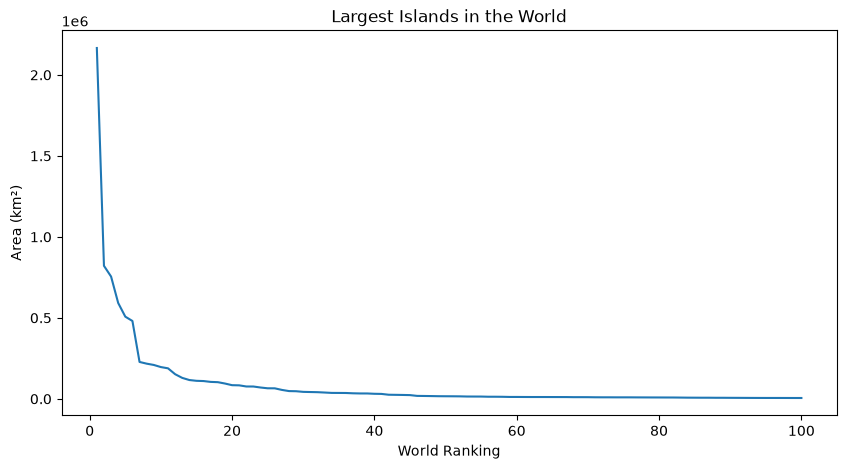

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(sorted_islands['rank'], sorted_islands['area'])

plt.xlabel('World Ranking')
plt.ylabel('Area (km²)')
plt.title('Largest Islands in the World')

plt.show()

### Analysis 3: Island Area Distribution

The line graph shows a steep decline in island area among the highest-ranked islands.

Greenland is significantly larger than the other islands in the dataset. As the ranking increases, island areas decrease and the curve gradually flattens.

This suggests that a small number of islands account for a disproportionately large share of the total area represented in the dataset.

In [10]:
df['countries'].str.contains(',')

0     False
1      True
2     False
3     False
4     False
      ...  
95    False
96    False
97    False
98     True
99    False
Name: countries, Length: 100, dtype: bool

In [11]:
shared_islands = df[df['countries'].str.contains(',')]

shared_islands

,region,island,area,countries,climate,rank
1,Antarctic,Kerguelen,6200,"Antarctic Lands, France",temperate,91
23,Asia,Borneo,755000,"Indonesia, Malaysia, Brunei",tropics,3
45,Europe,Ireland,84421,"Ireland, United Kingdom",temperate,20
50,Europe,Cyprus,9251,"Cyprus, United Kingdom",temperate,76
73,North America,Hispaniola,76192,"Dominican Republic, Haiti",tropics,23
86,Oceania,New Guinea,821400,"Papua New Guinea, Indonesia",tropics,2
98,South America,Isla Grande de Tierra del Fuego,47992,"Chile, Argentina",temperate,28


In [12]:
shared_islands.shape[0]

7

In [ ]:
### Analysis 4: Islands Shared by Multiple Countries

Using the `str.contains()` method, we identified seven records with multiple country or territory names separated by commas.

Examples include Borneo, Hispaniola, New Guinea, Ireland, and Isla Grande de Tierra del Fuego.

However, the presence of a comma does not necessarily indicate that an island is divided between multiple sovereign countries. The results require geographical and political interpretation.